# Prueba con cualquier dataset: ¿funciona nuestro DBSCAN?

En la entrega, el profesor nos puede dar **su propio CSV** y pedirnos que lo corramos en vivo. Lo
más probable es que lo genere con la celda 1 de `DBSCAN_noise.ipynb` (p14), cambiando `n_points`
y quizá `random_state`. Este notebook:

1. **Compila** las tres versiones desde `src/` (siempre el código actual).
2. **Parte A:** corre serial, P1 y P2 sobre **un CSV** (el del profesor) y compara las etiquetas
   contra el DBSCAN de scikit-learn y entre ellas. Escribe `<n>_results.csv` junto al CSV de
   entrada, para que la celda 2 de `DBSCAN_noise.ipynb` lo pueda dibujar, y aquí mismo dibuja
   sklearn y nuestro resultado lado a lado.
3. **Parte B:** corre una **batería de datasets aleatorios** distintos al del experimento (otras
   semillas, otras formas, coordenadas negativas, puntos repetidos, casos chicos, otros `eps`) y
   reporta cuáles pasan.
4. **Parte C:** recrea la carita de la portada del PDF y la dibuja.
5. **Parte D:** prueba otros formatos de archivo (encabezado, líneas vacías, `\r\n`).

**Criterio de "funciona":** P1 y P2 dan **exactamente** las mismas etiquetas que la serial con
cualquier número de hilos y cualquier k, y la serial da las mismas etiquetas que sklearn.

> Para usarlo con el archivo del profesor: pon la ruta en `RUTA_CSV` (celda de configuración) y
> corre todo (*Run All*).

In [1]:
# ===== Configuración: lo único que hay que cambiar =====
RUTA_CSV = None        # p. ej. "/Users/.../4000_data.csv" (el del profesor)
# Si RUTA_CSV es None, se genera <N_PUNTOS>_data.csv aquí mismo con el código EXACTO de la
# celda 1 de DBSCAN_noise.ipynb, como lo haría el profesor:
N_PUNTOS = 4000
RANDOM_STATE = 11      # el del notebook del curso; cámbialo para probar otros datos
EPS = 0.03
MIN_SAMPLES = 10
HILOS = [1, 8, 16, 32]           # {1, virtuales/2, virtuales, virtuales*2} en nuestra Mac
KS = [2, 4, 8, 16, 32, 64]

In [2]:
import os
import re
import subprocess
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs, make_circles, make_moons

# Carpeta del proyecto: este notebook vive en proyectos/dbscan/notebooks/
PROYECTO = Path.cwd().resolve()
while not (PROYECTO / "src" / "serial").exists():
    if PROYECTO.parent == PROYECTO:
        raise RuntimeError("Abre este notebook desde proyectos/dbscan/notebooks/")
    PROYECTO = PROYECTO.parent

FUENTES = {
    "serial": PROYECTO / "src" / "serial" / "dbscan_serial.cpp",
    "p1": PROYECTO / "src" / "parallel" / "dbscan_p1.cpp",
    "p2": PROYECTO / "src" / "parallel-2" / "dbscan_p2.cpp",
}
# Mismas banderas que el experimento (Mac Intel + libomp de Homebrew).
COMPILAR = ["clang++", "-std=c++17", "-O2", "-Xpreprocessor", "-fopenmp",
            "-I/usr/local/opt/libomp/include", "-L/usr/local/opt/libomp/lib", "-lomp"]

# Binarios y archivos temporales en una carpeta aparte (no ensucia el repo).
TMP = Path(tempfile.mkdtemp(prefix="dbscan_prueba_"))
BIN = {}
for nombre, fuente in FUENTES.items():
    BIN[nombre] = TMP / nombre
    subprocess.run(COMPILAR + [str(fuente), "-o", str(BIN[nombre])], check=True)
print("Compilado en", TMP)

Compilado en /var/folders/2q/26k3vxq96q71kjlrx_xm2jph0000gn/T/dbscan_prueba_kch9vies


In [3]:
def empieza_con_numero(linea):
    # Misma regla que empiezaConNumero() en C++: así sklearn ve los mismos puntos.
    linea = linea.lstrip(" \t")
    return linea != "" and (linea[0].isdigit() or linea[0] in "-+.")


def leer_puntos(ruta):
    # Lee x,y igual que leerPuntos() en C++: columnas 0 y 1 separadas por coma,
    # saltando líneas vacías y el encabezado (si lo hay).
    with open(ruta) as f:
        datos = [l for l in f if empieza_con_numero(l)]
    if not datos:
        return np.zeros((0, 2))
    return np.loadtxt(datos, delimiter=",", usecols=(0, 1), ndmin=2)


def correr(version, ruta, eps, min_samples, hilos=1, k=2):
    # Corre un binario y regresa (tiempo_segundos, etiquetas 0/1 como arreglo).
    salida = TMP / f"salida_{version}.csv"
    cmd = [str(BIN[version]), str(ruta), str(salida), str(eps), str(min_samples)]
    if version != "serial":
        cmd.append(str(hilos))
    if version == "p2":
        cmd.append(str(k))
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=600)
    if r.returncode != 0:
        raise RuntimeError(f"{version} falló: {r.stderr.strip() or r.stdout.strip()}")
    t = float(re.search(r"tiempo_segundos=([0-9.eE+-]+)", r.stderr).group(1))
    if os.path.getsize(salida) == 0:
        return t, np.zeros(0, dtype=int)
    etiquetas = np.loadtxt(salida, delimiter=",", ndmin=2)[:, 2].astype(int)
    return t, etiquetas


def etiquetas_sklearn(puntos, eps, min_samples):
    # 1 = core o border (no ruido), 0 = ruido; igual que nuestro CSV de salida.
    if len(puntos) == 0:
        return np.zeros(0, dtype=int)
    clusters = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(puntos)
    return np.where(clusters == -1, 0, 1)


def probar(ruta, eps, min_samples, hilos=HILOS, ks=KS):
    # Corre serial, P1 (todos los hilos) y P2 (todos los hilos x todas las k).
    # Regresa un dict con los resultados y cuántas etiquetas difieren.
    puntos = leer_puntos(ruta)
    ref = etiquetas_sklearn(puntos, eps, min_samples)
    t_serial, serial = correr("serial", ruta, eps, min_samples)
    res = {"n": len(puntos), "ruido": int((serial == 0).sum()),
           "dif_sklearn": int((serial != ref).sum()), "t_serial": t_serial,
           "dif_p1": 0, "dif_p2": 0, "tiempos": {}}
    for h in hilos:
        t, e = correr("p1", ruta, eps, min_samples, h)
        res["dif_p1"] = max(res["dif_p1"], int((e != serial).sum()))
        res["tiempos"][("p1", h, 0)] = t
        for k in ks:
            t, e = correr("p2", ruta, eps, min_samples, h, k)
            res["dif_p2"] = max(res["dif_p2"], int((e != serial).sum()))
            res["tiempos"][("p2", h, k)] = t
    res["ok"] = res["dif_sklearn"] == 0 and res["dif_p1"] == 0 and res["dif_p2"] == 0
    return res, puntos, serial, ref

## Parte A: el dataset del profesor (o uno de prueba)

Si `RUTA_CSV` es `None`, primero se genera `<N_PUNTOS>_data.csv` en esta carpeta con el código de la
celda 1 de `DBSCAN_noise.ipynb`, copiado tal cual (solo cambian los nombres `N_PUNTOS` y
`RANDOM_STATE`).

In [4]:
if RUTA_CSV is None:
    # --- Celda 1 de DBSCAN_noise.ipynb (sin la parte de graficar) ---
    n_points = N_PUNTOS
    points, y_true = make_blobs(n_samples=n_points,
                                centers=4,
                                cluster_std=0.06,
                                random_state=RANDOM_STATE,
                                center_box=(0, 1.0))
    points = np.round(np.abs(points[:, ::-1]), 3)
    np.savetxt(str(n_points)+"_data.csv", points, delimiter=",",  fmt="%.3f")
    # ---
    ruta = Path(str(n_points) + "_data.csv").resolve()
else:
    ruta = Path(RUTA_CSV).expanduser().resolve()

res, puntos, serial, ref = probar(ruta, EPS, MIN_SAMPLES)

# <n>_results.csv junto a la entrada, con la salida de la serial (= P1 = P2 si todo coincide):
# es el archivo que lee la celda 2 de DBSCAN_noise.ipynb.
prefijo = ruta.name[:-len("_data.csv")] if ruta.name.endswith("_data.csv") else ruta.stem
ruta_resultados = ruta.with_name(f"{prefijo}_results.csv")
correr("serial", ruta, EPS, MIN_SAMPLES)
(TMP / "salida_serial.csv").replace(ruta_resultados)

print(f"Archivo: {ruta}")
print(f"n = {res['n']}, eps = {EPS}, min_samples = {MIN_SAMPLES}")
print(f"Puntos de ruido (nuestra serial): {res['ruido']}   (sklearn: {(ref == 0).sum()})")
print(f"Etiquetas distintas  serial vs sklearn: {res['dif_sklearn']}")
print(f"Etiquetas distintas  P1 vs serial (peor caso de {len(HILOS)} hilos): {res['dif_p1']}")
print(f"Etiquetas distintas  P2 vs serial (peor caso de {len(HILOS) * len(KS)} configs): {res['dif_p2']}")
print("RESULTADO:", "✅ TODO COINCIDE" if res["ok"] else "❌ HAY DIFERENCIAS")
print(f"Resultados escritos en: {ruta_resultados}")

print(f"\nTiempo serial: {res['t_serial']:.4f} s")
print("Speedup (una sola corrida, solo como referencia):")
print("hilos   P1    " + "  ".join(f"P2 k={k:<2}" for k in KS))
for h in HILOS:
    fila = f"{h:5}  {res['t_serial'] / res['tiempos'][('p1', h, 0)]:5.1f}  "
    fila += "  ".join(f"{res['t_serial'] / res['tiempos'][('p2', h, k)]:7.1f}" for k in KS)
    print(fila)

Archivo: /Users/monilira/desarrollo/universidad/computo_paralelo_26/proyectos/dbscan/notebooks/4000_data.csv
n = 4000, eps = 0.03, min_samples = 10
Puntos de ruido (nuestra serial): 59   (sklearn: 59)
Etiquetas distintas  serial vs sklearn: 0
Etiquetas distintas  P1 vs serial (peor caso de 4 hilos): 0
Etiquetas distintas  P2 vs serial (peor caso de 24 configs): 0
RESULTADO: ✅ TODO COINCIDE
Resultados escritos en: /Users/monilira/desarrollo/universidad/computo_paralelo_26/proyectos/dbscan/notebooks/4000_results.csv

Tiempo serial: 0.0127 s
Speedup (una sola corrida, solo como referencia):
hilos   P1    P2 k=2   P2 k=4   P2 k=8   P2 k=16  P2 k=32  P2 k=64
    1    1.0      1.3      2.3      3.4      3.9      4.2      3.7
    8    3.9      2.2      4.3      8.4     11.7     14.6     12.5
   16    6.1      1.7      3.4      5.7      9.1     10.2     11.4
   32    5.1      1.7      2.8      4.5      6.8      8.1      8.1


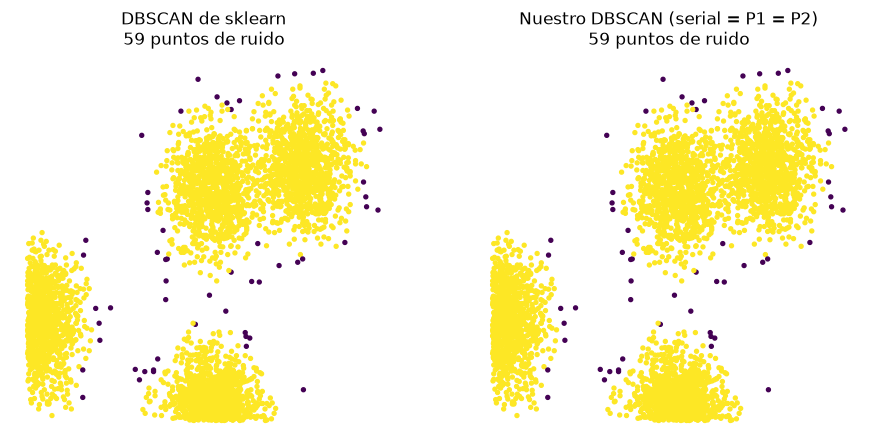

In [5]:
# Mismo dibujo que DBSCAN_noise.ipynb: sklearn a la izquierda, nuestro programa a la derecha.
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, etiquetas, titulo in [(ax[0], ref, "DBSCAN de sklearn"),
                             (ax[1], serial, "Nuestro DBSCAN (serial = P1 = P2)")]:
    a.scatter(puntos[:, 0], puntos[:, 1], c=etiquetas, s=8)
    a.set_title(f"{titulo}\n{(etiquetas == 0).sum()} puntos de ruido")
    a.set_xticks([]); a.set_yticks([]); a.set_frame_on(False)
plt.show()

## Parte B: batería de datasets aleatorios

Cada caso cambia algo respecto al experimento, para buscar dónde se podría romper el programa:

| Qué se prueba | Por qué podría fallar |
|---|---|
| La receta exacta de `DBSCAN_noise.ipynb` con otros `n_points` (incluidos tamaños que no están en el experimento) | Es lo que más probablemente use el profesor. |
| Otras semillas y otros `eps` / `min_samples` con la misma receta | Que solo funcione con los datos y parámetros que ya probamos. |
| La carita de la portada del PDF (anillo, ojos, boca) | El anillo cruza casi todas las celdas de P2: el halo tiene que encontrar vecinos del otro lado en todas las fronteras. |
| Otras formas: lunas, dos círculos concéntricos, ruido uniforme | Clusters que no son blobs redondos. |
| Coordenadas negativas (sin `abs`) | La cuadrícula de P2 empieza en `x_min`, `y_min`, que ya no son ≥ 0. |
| Todos los puntos en una línea (`alto = 0`) | P2 divide entre el alto de la celda: hay un caso especial para que no divida entre 0. |
| Puntos repetidos | Distancia 0 entre puntos distintos. |
| Muy pocos puntos (1, 5) y más celdas que puntos | Celdas vacías en P2; `min_samples` mayor que n. |
| Otros `eps` y `min_samples` | Un `eps` más grande que una celda de la cuadrícula hace que el halo cubra a las celdas vecinas. |
| Puntos exactamente a distancia `eps` | Redondeo de punto flotante justo en la frontera. |

Se usan hilos {1, 8, 32} y todas las k para que la batería tarde menos de un minuto (~25 s en nuestra Mac).

In [6]:
def blobs_curso(n, semilla):
    p, _ = make_blobs(n_samples=n, centers=4, cluster_std=0.06,
                      random_state=semilla, center_box=(0, 1.0))
    return np.round(np.abs(p[:, ::-1]), 3)


def carita(n=10000, semilla=0):
    # La "paleta payaso" de la portada del PDF (p1, p3): anillo, dos ojos, boca y ruido.
    rng = np.random.default_rng(semilla)
    m_anillo, m_boca, m_ojo = int(0.60 * n), int(0.22 * n), int(0.08 * n)
    m_ruido = n - m_anillo - m_boca - 2 * m_ojo                    # ~2% de ruido
    a = rng.uniform(0, 2 * np.pi, m_anillo)                        # anillo de radio 0.42
    r = 0.42 + rng.normal(0, 0.015, m_anillo)
    anillo = np.column_stack([0.5 + r * np.cos(a), 0.5 + r * np.sin(a)])
    a = rng.uniform(np.radians(200), np.radians(340), m_boca)      # boca: arco de abajo
    r = 0.22 + rng.normal(0, 0.02, m_boca)
    boca = np.column_stack([0.5 + r * np.cos(a), 0.48 + r * np.sin(a)])
    ojo_izq = rng.normal([0.36, 0.64], 0.03, (m_ojo, 2))
    ojo_der = rng.normal([0.64, 0.64], 0.03, (m_ojo, 2))
    ruido = rng.uniform(0.02, 0.98, (m_ruido, 2))
    return np.round(np.vstack([anillo, boca, ojo_izq, ojo_der, ruido]), 3)


rng = np.random.default_rng(7)
casos = [
    # (nombre, puntos, eps, min_samples)
    ("notebook tal cual, n=4000",         blobs_curso(4000, 11), 0.03, 10),
    ("notebook, n=7777",                  blobs_curso(7777, 11), 0.03, 10),
    ("notebook, n=30000",                 blobs_curso(30000, 11), 0.03, 10),
    ("notebook, eps=0.02, ms=5",          blobs_curso(8000, 11), 0.02, 5),
    ("notebook, eps=0.05, ms=20",         blobs_curso(8000, 11), 0.05, 20),
    ("curso, semilla 1, n=5000",          blobs_curso(5000, 1), 0.03, 10),
    ("curso, semilla 99, n=12345",        blobs_curso(12345, 99), 0.03, 10),
    ("curso, semilla 2026, n=20000",      blobs_curso(20000, 2026), 0.03, 10),
    ("8 blobs más dispersos",             np.round(np.abs(make_blobs(8000, centers=8, cluster_std=0.1,
                                                   random_state=3, center_box=(0, 1))[0]), 3), 0.03, 10),
    ("lunas con ruido",                   np.round(make_moons(6000, noise=0.08, random_state=4)[0], 3), 0.05, 8),
    ("carita del PDF (paleta payaso)",    carita(10000, 0), 0.03, 10),
    ("carita, otra semilla, n=20000",     carita(20000, 1), 0.03, 10),
    ("dos círculos concéntricos",         np.round(make_circles(6000, noise=0.05, factor=0.4,
                                                   random_state=5)[0], 3), 0.04, 8),
    ("ruido uniforme",                    np.round(rng.uniform(0, 1, (5000, 2)), 3), 0.02, 4),
    ("coordenadas negativas",             np.round(make_blobs(6000, centers=4, cluster_std=0.06,
                                                   random_state=6, center_box=(-1, 1))[0], 3), 0.03, 10),
    ("escala grande (0 a 1000)",          np.round(rng.uniform(0, 1000, (4000, 2)), 3), 25.0, 5),
    ("todos en una línea (y = 0.5)",      np.column_stack([np.round(rng.uniform(0, 1, 3000), 3),
                                                           np.full(3000, 0.5)]), 0.01, 5),
    ("puntos repetidos",                  np.repeat(np.round(rng.uniform(0, 1, (300, 2)), 3), 4, axis=0), 0.03, 4),
    ("cuadrícula exacta a distancia eps", np.array([[i * 0.03, j * 0.03] for i in range(40)
                                                    for j in range(40)]).round(3), 0.03, 5),
    ("1 punto",                           np.array([[0.5, 0.5]]), 0.03, 1),
    ("5 puntos, min_samples > n",         np.round(rng.uniform(0, 1, (5, 2)), 3), 0.5, 10),
    ("eps grande (0.3)",                  blobs_curso(4000, 8), 0.3, 50),
    ("min_samples = 1",                   blobs_curso(4000, 9), 0.03, 1),
]

filas = []
inicio = time.time()
for nombre, pts, eps, ms in casos:
    ruta_caso = TMP / "caso.csv"
    np.savetxt(ruta_caso, pts, delimiter=",", fmt="%.3f")
    try:
        r, *_ = probar(ruta_caso, eps, ms, hilos=[1, 8, 32])
        filas.append((nombre, r["n"], eps, ms, r["ruido"], r["dif_sklearn"], r["dif_p1"],
                      r["dif_p2"], "✅" if r["ok"] else "❌"))
    except Exception as e:
        filas.append((nombre, len(pts), eps, ms, "-", "-", "-", "-", f"💥 {e}"))

print(f"{'caso':36} {'n':>6} {'eps':>6} {'ms':>3} {'ruido':>6} {'≠sk':>4} {'≠P1':>4} {'≠P2':>4}")
for f in filas:
    print(f"{f[0]:36} {f[1]:6} {f[2]:6} {f[3]:3} {f[4]:>6} {f[5]:>4} {f[6]:>4} {f[7]:>4}  {f[8]}")
print(f"\n{sum(f[8] == '✅' for f in filas)} de {len(filas)} casos pasan "
      f"({time.time() - inicio:.0f} s).")

caso                                      n    eps  ms  ruido  ≠sk  ≠P1  ≠P2
notebook tal cual, n=4000              4000   0.03  10     59    0    0    0  ✅
notebook, n=7777                       7777   0.03  10     48    0    0    0  ✅
notebook, n=30000                     30000   0.03  10     40    0    0    0  ✅
notebook, eps=0.02, ms=5               8000   0.02   5     99    0    0    0  ✅
notebook, eps=0.05, ms=20              8000   0.05  20     11    0    0    0  ✅
curso, semilla 1, n=5000               5000   0.03  10     48    0    0    0  ✅
curso, semilla 99, n=12345            12345   0.03  10     54    0    0    0  ✅
curso, semilla 2026, n=20000          20000   0.03  10     62    0    0    0  ✅
8 blobs más dispersos                  8000   0.03  10    240    0    0    0  ✅
lunas con ruido                        6000   0.05   8    160    0    0    0  ✅
carita del PDF (paleta payaso)        10000   0.03  10     91    0    0    0  ✅
carita, otra semilla, n=20000         20000

## Parte C: la carita del PDF ("paleta payaso")

La portada del proyecto (p1, p3) muestra una carita: un anillo, dos ojos y una boca, con puntos de
ruido alrededor. Aquí la recreamos con `carita()` (definida en la Parte B) y la corremos igual que el
dataset del profesor. A la izquierda se colorea cada cluster que encuentra sklearn, como en la
portada; a la derecha está nuestro resultado (ruido en morado).

Es una prueba exigente para P2. El anillo pasa por casi todas las celdas de la cuadrícula, así que
cada punto del anillo cerca de una frontera depende del **halo** para encontrar a sus vecinos del
otro lado. Las líneas punteadas muestran la cuadrícula con k = 16.

n = 10000, clusters de sklearn = 4, ruido: nuestro = 91, sklearn = 91
Etiquetas distintas  serial vs sklearn: 0  |  P1 vs serial: 0  |  P2 vs serial: 0
RESULTADO: ✅ TODO COINCIDE


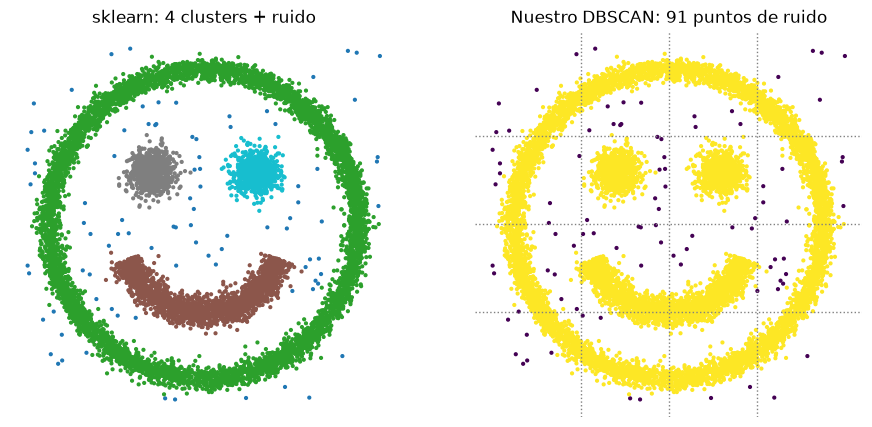

In [7]:
pts_carita = carita(10000, 0)
ruta_carita = TMP / "carita_data.csv"
np.savetxt(ruta_carita, pts_carita, delimiter=",", fmt="%.3f")

res_c, puntos_c, nuestro_c, ref_c = probar(ruta_carita, 0.03, 10)
clusters_c = DBSCAN(eps=0.03, min_samples=10).fit_predict(puntos_c)
print(f"n = {res_c['n']}, clusters de sklearn = {clusters_c.max() + 1}, "
      f"ruido: nuestro = {res_c['ruido']}, sklearn = {(ref_c == 0).sum()}")
print(f"Etiquetas distintas  serial vs sklearn: {res_c['dif_sklearn']}  |  "
      f"P1 vs serial: {res_c['dif_p1']}  |  P2 vs serial: {res_c['dif_p2']}")
print("RESULTADO:", "✅ TODO COINCIDE" if res_c["ok"] else "❌ HAY DIFERENCIAS")

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
colores = np.where(clusters_c == -1, -1, clusters_c)
ax[0].scatter(puntos_c[:, 0], puntos_c[:, 1], c=colores, cmap="tab10", s=4)
ax[0].set_title(f"sklearn: {clusters_c.max() + 1} clusters + ruido")
ax[1].scatter(puntos_c[:, 0], puntos_c[:, 1], c=nuestro_c, s=4)
ax[1].set_title(f"Nuestro DBSCAN: {(nuestro_c == 0).sum()} puntos de ruido")
x0, x1 = puntos_c[:, 0].min(), puntos_c[:, 0].max()
y0, y1 = puntos_c[:, 1].min(), puntos_c[:, 1].max()
for i in range(1, 4):  # cuadrícula 4 x 4 de P2 con k = 16
    ax[1].axvline(x0 + i * (x1 - x0) / 4, color="gray", linestyle=":", linewidth=1)
    ax[1].axhline(y0 + i * (y1 - y0) / 4, color="gray", linestyle=":", linewidth=1)
for a in ax:
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_frame_on(False)
plt.show()

## Parte D: otros formatos de archivo

`DBSCAN_noise.ipynb` guarda `x,y` por línea, separado por coma, con 3 decimales y **sin
encabezado**. Por si el CSV llega de otro lado, `leerPuntos()` se salta las líneas que no empiezan
con un número (`empiezaConNumero()`), así que:

- **Sí funcionan:** encabezado `x,y` (pandas lo pone), líneas vacías, saltos de línea de Windows
  (`\r\n`), columnas extra (se ignoran), notación científica y números negativos.
- **No funciona:** separador `;`. No truena, pero lee mal los números. Hay que convertirlo a comas.

In [8]:
# Demostración: el mismo dataset con encabezado, línea vacía y \r\n da las mismas etiquetas.
pts = blobs_curso(3000, 11)
limpio, raro = TMP / "limpio.csv", TMP / "raro.csv"
np.savetxt(limpio, pts, delimiter=",", fmt="%.3f")
lineas = [f"{a:.3f},{b:.3f}" for a, b in pts]
raro.write_text("x,y\r\n" + "\r\n".join(lineas[:1500]) + "\r\n\r\n" + "\r\n".join(lineas[1500:]) + "\r\n")
for v, args in [("serial", {}), ("p1", {"hilos": 8}), ("p2", {"hilos": 8, "k": 16})]:
    _, a = correr(v, limpio, 0.03, 10, **args)
    _, b = correr(v, raro, 0.03, 10, **args)
    print(f"{v:6} con encabezado + línea vacía + \\r\\n: {len(b)} puntos, "
          f"{'mismas etiquetas ✅' if np.array_equal(a, b) else 'DIFERENTE ❌'}")

serial con encabezado + línea vacía + \r\n: 3000 puntos, mismas etiquetas ✅
p1     con encabezado + línea vacía + \r\n: 3000 puntos, mismas etiquetas ✅
p2     con encabezado + línea vacía + \r\n: 3000 puntos, mismas etiquetas ✅
